<a href="https://colab.research.google.com/github/natacherchum/FuzzyLogic_in_SupplyChainManagement/blob/main/ARTICLE_fyzzy_mamdani_skfuzzy_ipynb%22.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
!pip install -q scikit-fuzzy

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import skfuzzy as fuzz
from skfuzzy import control as ctrl

In [ ]:
# 1. Define variables and their universes of discourse
coverage = ctrl.Antecedent(np.arange(0, 15, 1), "coverage")
demand = ctrl.Antecedent(np.arange(-50, 51, 1), "demand")

priority = ctrl.Consequent(np.linspace(0, 1, 101), "priority")


In [ ]:
# 2. Define membership functions

# Inventory coverage, days of demand
coverage["critical"] = fuzz.trapmf(coverage.universe, [0, 0, 2, 5])
coverage["limited"] = fuzz.trimf(coverage.universe, [2, 5, 8])
coverage["sufficient"] = fuzz.trapmf(coverage.universe, [5, 8, 14, 14])

# Change in demand, percent
demand["decreasing"] = fuzz.trimf(demand.universe, [-50, -50, 0])
demand["stable"] = fuzz.trimf(demand.universe, [-50, 0, 50])
demand["increasing"] = fuzz.trimf(demand.universe, [0, 50, 50])

# Request fulfilment priority
priority["low"] = fuzz.trimf(priority.universe, [0, 0, 0.5])
priority["medium"] = fuzz.trimf(priority.universe, [0, 0.5, 1])
priority["high"] = fuzz.trimf(priority.universe, [0.5, 1, 1])

# Use centroid defuzzification
priority.defuzzify_method = "centroid"


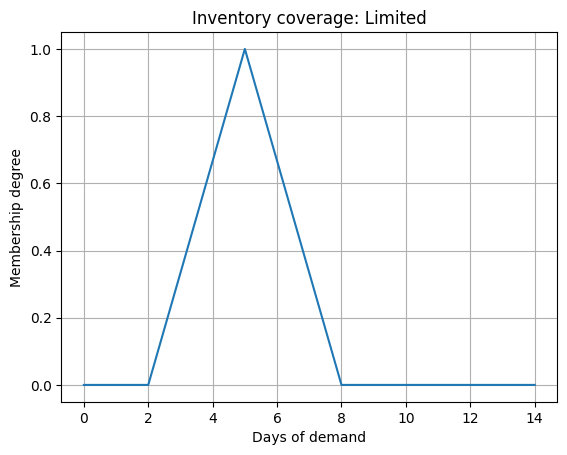

In [ ]:
#Plotting the Membership Function for the “Limited” Term
plt.plot(coverage.universe, coverage["limited"].mf)
plt.title("Inventory coverage: Limited")
plt.xlabel("Days of demand")
plt.ylabel("Membership degree")
plt.grid()
plt.show()

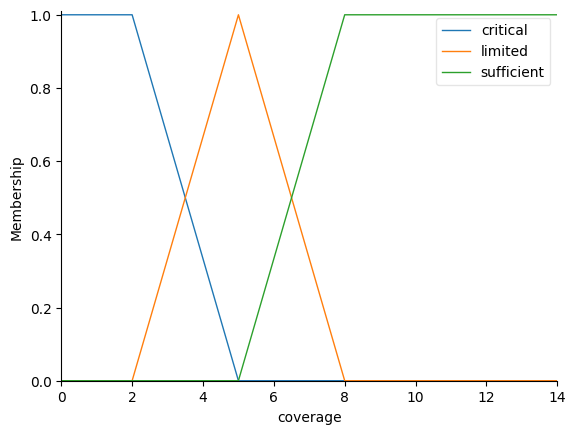

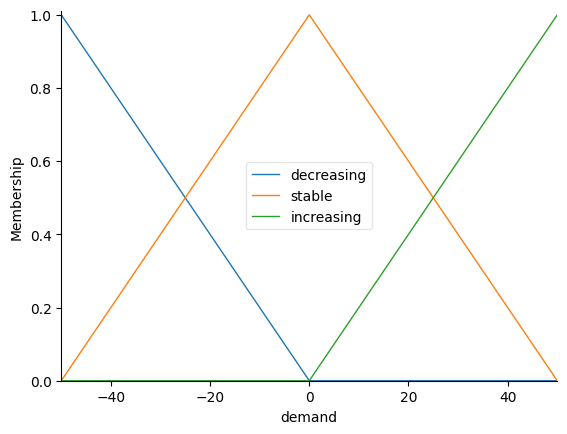

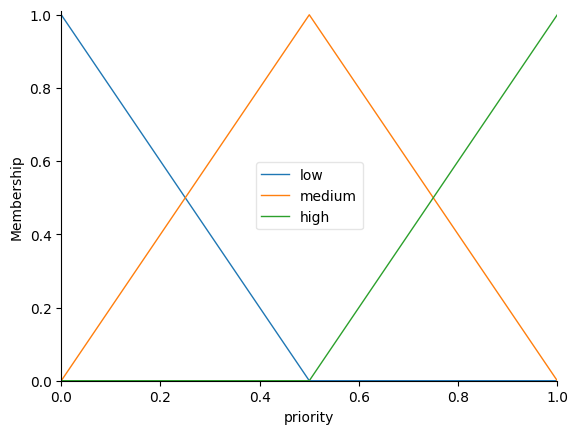

In [ ]:
# Plot the membership functions for all variables
coverage.view()
demand.view()
priority.view()
plt.show()

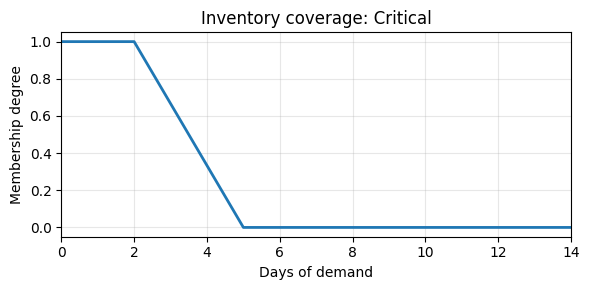

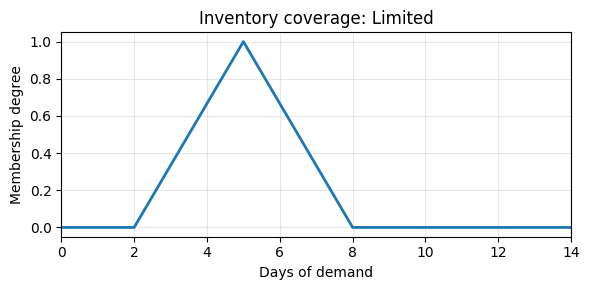

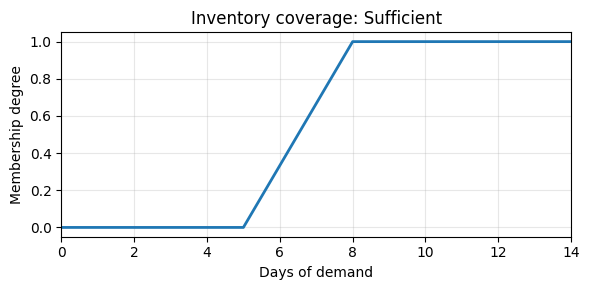

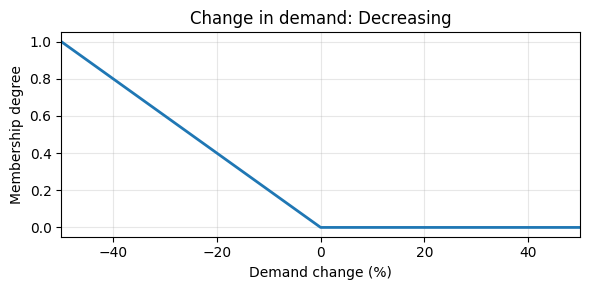

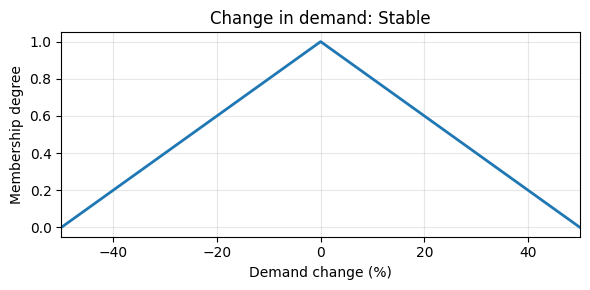

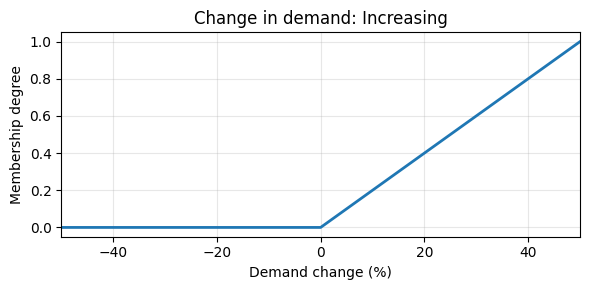

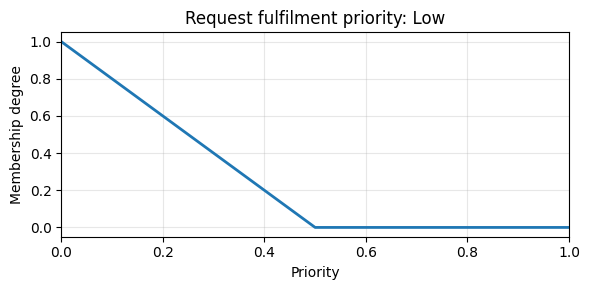

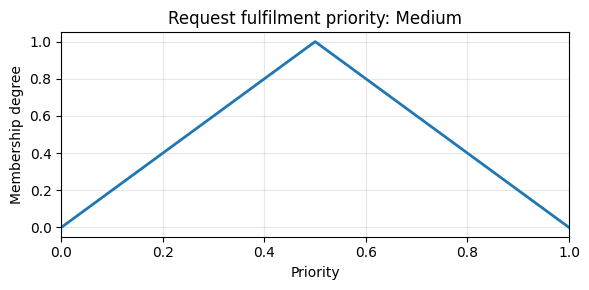

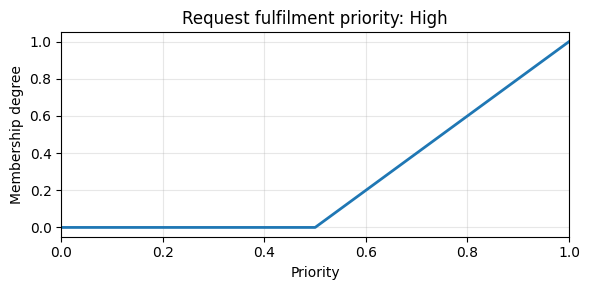

In [ ]:
## Plot the membership function of a selected linguistic term
def plot_membership(variable, term, title, xlabel):
    plt.figure(figsize=(6, 3))
    plt.plot(
        variable.universe,
        variable[term].mf,
        linewidth=2,
    )
    plt.title(title)
    plt.xlabel(xlabel)
    plt.ylabel("Membership degree")
    plt.xlim(variable.universe[0], variable.universe[-1])
    plt.ylim(-0.05, 1.05)
    plt.grid(alpha=0.3)
    plt.tight_layout()
    plt.show()


# Inventory coverage
plot_membership(
    coverage, "critical",
    "Inventory coverage: Critical", "Days of demand"
)

plot_membership(
    coverage, "limited",
    "Inventory coverage: Limited", "Days of demand"
)

plot_membership(
    coverage, "sufficient",
    "Inventory coverage: Sufficient", "Days of demand"
)


# Change in demand
plot_membership(
    demand, "decreasing",
    "Change in demand: Decreasing", "Demand change (%)"
)

plot_membership(
    demand, "stable",
    "Change in demand: Stable", "Demand change (%)"
)

plot_membership(
    demand, "increasing",
    "Change in demand: Increasing", "Demand change (%)"
)


# Request fulfilment priority
plot_membership(
    priority, "low",
    "Request fulfilment priority: Low", "Priority"
)

plot_membership(
    priority, "medium",
    "Request fulfilment priority: Medium", "Priority"
)

plot_membership(
    priority, "high",
    "Request fulfilment priority: High", "Priority"
)

In [ ]:
# 3. Define the rule base
rules = [
    ctrl.Rule(coverage["critical"] & demand["decreasing"], priority["high"]),
    ctrl.Rule(coverage["critical"] & demand["stable"], priority["high"]),
    ctrl.Rule(coverage["critical"] & demand["increasing"], priority["high"]),

    ctrl.Rule(coverage["limited"] & demand["decreasing"], priority["low"]),
    ctrl.Rule(coverage["limited"] & demand["stable"], priority["medium"]),
    ctrl.Rule(coverage["limited"] & demand["increasing"], priority["high"]),

    ctrl.Rule(coverage["sufficient"] & demand["decreasing"], priority["low"]),
    ctrl.Rule(coverage["sufficient"] & demand["stable"], priority["low"]),
    ctrl.Rule(coverage["sufficient"] & demand["increasing"], priority["medium"]),
]
# Mamdani inference: minimum for AND and clipping, maximum for aggregation
system = ctrl.ControlSystem(rules)

# 4. Calculate priorities for the three stores
# Each tuple contains: (inventory coverage in days, demand change in percent)
stores = {
    "A": (2, 0),
    "B": (4, 20),
    "C": (7, -10),
}

In [ ]:
for name, (coverage_days, demand_change) in stores.items():
    simulation = ctrl.ControlSystemSimulation(
        system,
        clip_to_bounds=False,
    )
    simulation.input["coverage"] = coverage_days
    simulation.input["demand"] = demand_change
    simulation.compute()

    print(f"Store {name}: priority = {simulation.output['priority']:.6f}")

Store A: priority = 0.833333
Store B: priority = 0.537681
Store C: priority = 0.388886
